In [ ]:
## This code is structured as follows:

## Feature engineering
## Train and test set split
## Feature scaling
## Feed-forward regressor neural network
## SHAP values analysis
## Plots (5E, 5G, S8C-F, S9)
## Visual cortex simulation


import random
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import IPython
import mpmath
from mpmath import mp
from mpmath import erfc
import seaborn as sns

from scipy.stats import zscore, boxcox, norm
from sklearn import preprocessing
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, PowerTransformer
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import make_regression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.feature_selection import SelectFromModel
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
#from sklearn.utils import parallel_backend
from tabulate import tabulate
import joblib
import math
from scipy.special import inv_boxcox

import shap

In [1291]:
# set working directory

In [ ]:
#load the train and test sets
X_all0 = scipy.io.loadmat("C:/Users/39349/Documents/SHAP VALUES ANALYSIS/X_final_final_final.mat")["X_new"]
X_all = np.hstack((X_all0[:,:5],X_all0[:,7:]))
Y_all = scipy.io.loadmat("C:/Users/39349/Documents/SHAP VALUES ANALYSIS/Y_response_no_subtraction.mat")["Y_new"][:,1]

#variable names
# var_names_all = ["DistA", "DistB", "AngleN", "AngleA", "AngleB", ("RespA", "RespB",) "Prestim_range", "Elect_dist", 
#                  "StimIntA", "StimIntB", "EF", "GeomMean", "MeanDist", "MeanDistSquared", "DistRatio", "LogStimInt",
#                  "IntDist1", "IntDist2", "IntDist3", "IntDist4", "IntDist5", "IntDist6", "IntDist7", "EF2"]

#load X coords
X_coords = scipy.io.loadmat("C:/Users/39349/Documents/SHAP VALUES ANALYSIS/X_coords.mat")["X_coords"]

In [1293]:
X_all.shape

(994, 10)

In [ ]:
# #calculate significance between each pair
# mu_X = np.mean(X_all[:,5])
# sigma_X = np.std(X_all[:,5], ddof=1)  # sample standard deviation
# n_X = len(X_all[:,5])

# mu_Y = np.mean(Y_all)
# sigma_Y = np.std(Y_all, ddof=1)  # sample standard deviation
# n_Y = len(Y_all)

# p_values = np.empty(len(Y_all))

# # Calculate p-values for each pair (a, b)
# for i in range(len(Y_all)):
#     a = X_all[i,5]  # specific value from X_all_orig
#     b = Y_all[i]       # specific value from Y_all

#     # Calculate the standard error of the difference
#     SE = np.sqrt((sigma_X ** 2) / n_X + (sigma_Y ** 2) / n_Y)

#     # Calculate the z-score (using 0 as the hypothesized difference)
#     z = (a - b) / SE
    
#     # Calculate the two-tailed p-value from the z-score
#     p_values[i] = 2 * (1 - norm.cdf(abs(z)))

# # print("P-values for each pair:", p_values)

In [ ]:
# Y_all_mod = np.zeros((len(Y_all),1))

# for i in range(len(Y_all)):
#     if p_values[i] > 0.001: # not significant
#         Y_all_mod[i] = 0
#     elif p_values[i] <= 0.001 and (Y_all[i] - X_all[i,5] > 0): # significant, positive modulation
#         Y_all_mod[i] = 1
#     elif p_values[i] <= 0.001 and (Y_all[i] - X_all[i,5] < 0): # significant, negative modulation
#         Y_all_mod[i] = -1
#     else:
#         Y_all_mod[i] = 2222 # in case of error
        
# # print(Y_all_mod)

In [1296]:
min_max_scaler = preprocessing.MinMaxScaler()

X_mmscaled = min_max_scaler.fit_transform(X_all)

In [ ]:
#add a few features
new_feats = np.zeros((X_all.shape[0],7))

for i in range(X_all.shape[0]):
    new_feats[i,0] = np.sqrt(X_all[i,0]*X_all[i,1]) #geometric mean
    new_feats[i,1] = (X_all[i,0]+X_all[i,1])/2 #mean distance
    new_feats[i,2] = (X_all[i,0]+X_all[i,1]/2)**2 #square of mean distance
    new_feats[i,3] = np.log10(X_all[i,7]*X_all[i,8]) #log of stimulation intensity
    new_feats[i,4] = ((X_all[i,7]+X_all[i,8])/2)/(X_all[i,0]+X_all[i,1])**2
    new_feats[i,5] = X_all[i,7]**2+X_all[i,8]**2
    new_feats[i,6] = X_all[i,0]*X_all[i,1]*np.cos(X_all[i,2])

correlations1 = [np.corrcoef(new_feats[:, i], Y_all)[0, 1] for i in range(new_feats.shape[1])]
correlations2 = [np.corrcoef(X_all[:, i], Y_all)[0, 1] for i in range(X_all.shape[1])]

In [1300]:
X_all = np.hstack((X_all, new_feats))

In [ ]:
# SPLIT INTO TRAIN AND TEST SET
rand_index = random.sample(range(X_all.shape[0]), X_all.shape[0]) #random indexes
X_all_rand = X_all[rand_index, :]
Y_all_rand = Y_all[rand_index]
X_coords_rand = X_coords[rand_index, :]

X_train = X_all_rand[:700,] 
X_test = X_all_rand[700:,] 
Y_train = Y_all_rand[:700] 
Y_test = Y_all_rand[700:]

X_all0_rand = X_all0[rand_index, :]
X_test_0 = X_all0_rand[700:,] #use only for modulation calculations

In [1302]:
# FEATURE SCALING WITH ROBUST SCALER (ROBUST TO OUTLIERS)
min_max_scaler = preprocessing.MinMaxScaler()

X_train_mmscaled = min_max_scaler.fit_transform(X_train)
X_test_mmscaled = min_max_scaler.transform(X_test)

In [1303]:
# scaler = StandardScaler()

# X_train_mmscaled = scaler.fit_transform(X_train)
# X_test_mmscaled = scaler.transform(X_test)
# min_max_scaler_y = preprocessing.MinMaxScaler()

# Y_train = min_max_scaler_y.fit_transform(Y_train.reshape(-1,1))
# Y_test = min_max_scaler_y.transform(Y_test.reshape(-1,1))

In [1304]:
Y_train, lambda_val = boxcox(Y_train + 1)
Y_test, lambda_val2 = boxcox(Y_test + 1)

In [1307]:
# RUN NEURAL NETWORK
regr = MLPRegressor(random_state=1,
                    hidden_layer_sizes=(100,100,100),
                    alpha = 0.0001,
                    max_iter=1000,
                    activation = 'relu',
                    solver = "adam").fit(X_train_mmscaled, Y_train.ravel())
Y_pred = regr.predict(X_test_mmscaled)
r2 = regr.score(X_test_mmscaled, Y_test)
print(r2)
mse = mean_squared_error(Y_test, Y_pred)
print(mse)

0.8267342575384882
0.014396042967078864


In [ ]:

# SHAP values analysis

# feature names (17 tot)
feature_names = [
    "distA", "distB", "angleN", "angleA", "angleB",
    "prestim_range", "electrode_dist", "stim1", "stim2", "efield",
    "geom_mean", "mean_dist", "sq_mean_dist",
    "log_stim_intensity", "normalized_dist",
    "sq_stim_sum", "electrode_dist_projection"
]


#variable names
# var_names_all = ["DistA", "DistB", "AngleN", "AngleA", "AngleB", "RespA", "RespB", "Prestim_range", "Elect_dist", 
#                  "StimIntA", "StimIntB", "EF", "GeomMean", "MeanDist", "MeanDistSquared", "DistRatio", "LogStimInt",
#                  "IntDist1", "IntDist2", "IntDist3", "IntDist4", "IntDist5", "IntDist6", "IntDist7", "EF2"]

#use background sample (100 points) to approximate the baseline (explainer slow on large datasets)
background = shap.sample(X_train_mmscaled, 100, random_state=42)
explainer = shap.KernelExplainer(regr.predict, background)

# compute SHAP values on test set
shap_values = explainer.shap_values(X_test_mmscaled, nsamples=500)


In [ ]:
# ── Precompute stats from SHAP values ─────────────────────────────────────────
mean_abs_shap = np.abs(shap_values).mean(axis=0)
std_abs_shap  = np.abs(shap_values).std(axis=0)
sorted_idx    = np.argsort(mean_abs_shap)  # ascending so top feature is at top
sorted_names  = [feature_names[i] for i in sorted_idx]
sorted_means  = mean_abs_shap[sorted_idx]
sorted_stds   = std_abs_shap[sorted_idx]
sorted_shap   = np.abs(shap_values)[:, sorted_idx]  # for boxplot



In [ ]:
# ── Violin plot of raw SHAP values centered on zero ───────────────────────────
sorted_shap_raw = shap_values[:, sorted_idx]  # raw, not absolute

fig, ax = plt.subplots(figsize=(8, 6))

parts = ax.violinplot(
    [sorted_shap_raw[:, i] for i in range(len(sorted_names))],
    vert=False,
    showmedians=False,
    showextrema=False
)

for pc in parts["bodies"]:
    pc.set_facecolor("steelblue")
    pc.set_alpha(0.6)
    
ax.axvline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_yticks(range(1, len(sorted_names) + 1))
ax.set_yticklabels(sorted_names)
ax.set_xlabel("SHAP value")
ax.set_title("Feature contributions")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("shap_violin_centered.png", dpi=150, bbox_inches="tight")
plt.savefig("shap_violin_centered.svg", bbox_inches="tight")
plt.close()

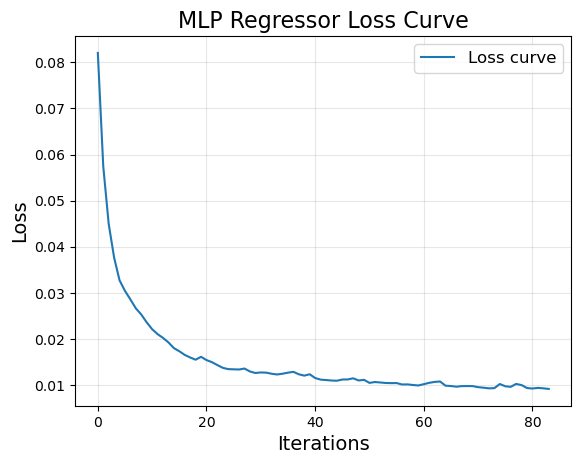

In [1262]:
# Plot of loss curve
plt.plot(regr.loss_curve_, label = "Loss curve")
plt.title('MLP Regressor Loss Curve', fontsize=16)
plt.xlabel('Iterations', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.grid(alpha=0.3)
plt.legend(fontsize=12)
plt.show()

In [ ]:
# Plot of learning rate
train_sizes, train_scores, val_scores = learning_curve(
    regr, 
    X_train_mmscaled, 
    Y_train.ravel(), 
    cv=5, 
    scoring='neg_mean_squared_error', 
    n_jobs=-1
)

# Calculate the mean and standard deviation for training and validation scores
train_scores_mean = -np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
val_scores_mean = -np.mean(val_scores, axis=1)
val_scores_std = np.std(val_scores, axis=1)

# Plot the learning curve
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_scores_mean, 'o-', color="blue", label="Training Score")
plt.plot(train_sizes, val_scores_mean, 'o-', color="green", label="Validation Score")
plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.2, color="blue")
plt.fill_between(train_sizes, val_scores_mean - val_scores_std, val_scores_mean + val_scores_std, alpha=0.2, color="green")

plt.title("MLP Regressor Learning Curve", fontsize=16)
plt.xlabel("Training Examples", fontsize=14)
plt.ylabel("Mean Squared Error (Negative)", fontsize=14)
plt.legend(loc="best", fontsize=12)
plt.grid(alpha=0.3)
plt.show()

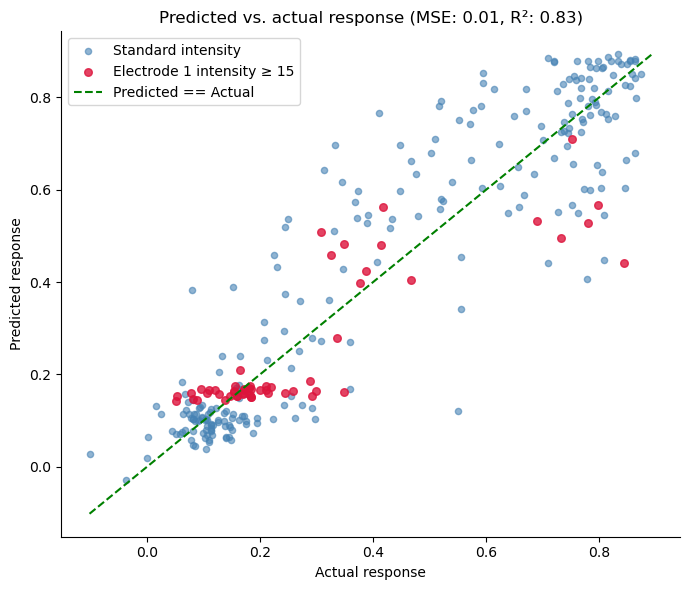

In [ ]:
# ── Highlight high-intensity samples (electrode 1 intensity > 15) ─────────────
# X_test was sliced from X_all_rand before scaling, so index into X_test directly

high_intensity_mask = X_test[:, 7] > 15

fig, ax = plt.subplots(figsize=(7, 6))

# Normal samples
ax.scatter(
    Y_test[~high_intensity_mask],
    Y_pred[~high_intensity_mask],
    alpha=0.6, s=20, color="steelblue", label="Standard intensity"
)

# High intensity samples
ax.scatter(
    Y_test[high_intensity_mask],
    Y_pred[high_intensity_mask],
    alpha=0.8, s=30, color="crimson", label="Electrode 1 intensity ≥ 15"
)

# Identity line
min_val = min(Y_test.min(), Y_pred.min())
max_val = max(Y_test.max(), Y_pred.max())
ax.plot([min_val, max_val], [min_val, max_val],
        color="green", linestyle="--", label="Predicted == Actual")

ax.set_xlabel("Actual response")
ax.set_ylabel("Predicted response")
ax.set_title(f"Predicted vs. actual response (MSE: {mse:.2f}, R²: {r2:.2f})")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("scatter_high_intensity.png", dpi=150, bbox_inches="tight")
plt.savefig("scatter_high_intensity.svg", bbox_inches="tight")
plt.show()
plt.close()

In [ ]:
def find_most_modulation(X_test, Y_test, rand_index):
    n = (X_test.shape[0] // 10)*3
    modulated_all = [(Y_test[i] - X_test[i, 5], i) for i in range(len(Y_test))]    
    modulated_10p = sorted(modulated_all, key=lambda x: abs(x[0]), reverse=True)[:n]
    
    return modulated_10p

modulated_10p = find_most_modulation(X_test_0, Y_test, rand_index[700:]) #get 10 percent highest modulated values with indexes


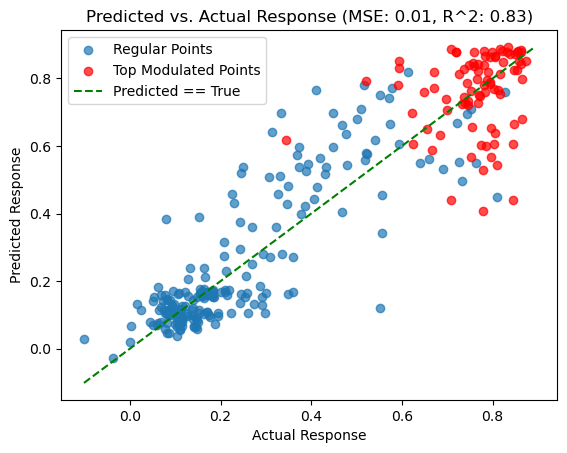

In [ ]:
# HIGHLIGHT THE TOP MOST HIGHLY MODULATED ONES
modulated_indices = [index for _, index in modulated_10p]
is_modulated = np.isin(range(len(Y_test)), modulated_indices)

plt.scatter(Y_test[~is_modulated], Y_pred[~is_modulated], label='Regular Points', alpha=0.7)
plt.scatter(Y_test[is_modulated], Y_pred[is_modulated], color='red', label='Top Modulated Points', alpha=0.7)

min_val = min(Y_test.min(), Y_pred.min())
max_val = max(Y_test.max(), Y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='green', linestyle='--', label='Predicted == True')

plt.title(f'Predicted vs. Actual Response (MSE: {mse:.2f}, R^2: {r2:.2f})')
plt.xlabel('Actual Response')
plt.ylabel('Predicted Response')
plt.legend()
plt.show()

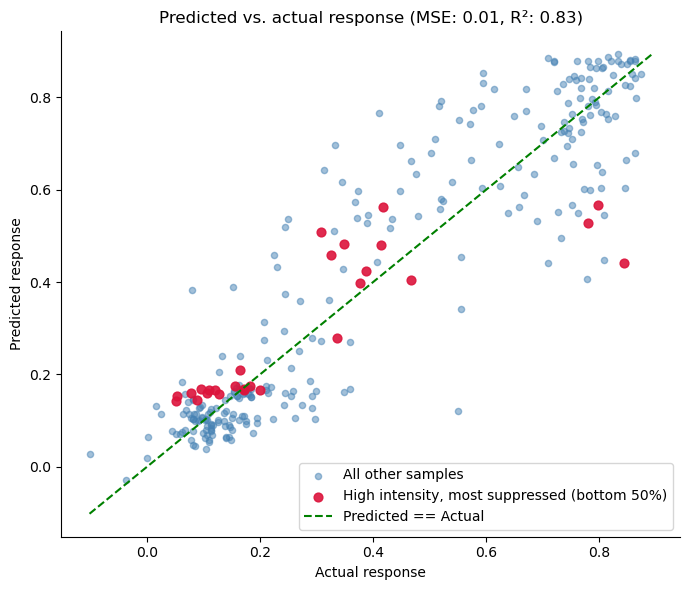

In [1313]:
## MODULATION OF SUPPRESSED HIGH RESPONDERS
# ── Compute modulation (double - single electrode response) ────────────────────
modulation = Y_test - X_test_0[:, 5]

# ── Within high-intensity subgroup, find bottom 50% by modulation ──────────────
high_int_indices = np.where(high_intensity_mask)[0]
high_int_modulation = modulation[high_int_indices]
threshold = np.median(high_int_modulation)
suppressed_mask = np.zeros(len(Y_test), dtype=bool)
suppressed_mask[high_int_indices[high_int_modulation <= threshold]] = True

# Three groups for plotting
normal_mask       = ~high_intensity_mask
high_not_suppressed = high_intensity_mask & ~suppressed_mask
high_suppressed     = high_intensity_mask & suppressed_mask

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(Y_test[~suppressed_mask], Y_pred[~suppressed_mask],
           alpha=0.5, s=20, color="steelblue", label="All other samples")

ax.scatter(Y_test[suppressed_mask], Y_pred[suppressed_mask],
           alpha=0.9, s=40, color="crimson", label="High intensity, most suppressed (bottom 50%)")

min_val = min(Y_test.min(), Y_pred.min())
max_val = max(Y_test.max(), Y_pred.max())
ax.plot([min_val, max_val], [min_val, max_val],
        color="green", linestyle="--", label="Predicted == Actual")

ax.set_xlabel("Actual response")
ax.set_ylabel("Predicted response")
ax.set_title(f"Predicted vs. actual response (MSE: {mse:.2f}, R²: {r2:.2f})")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("scatter_suppressed.png", dpi=150, bbox_inches="tight")
plt.savefig("scatter_suppressed.svg", bbox_inches="tight")
plt.show()
plt.close()

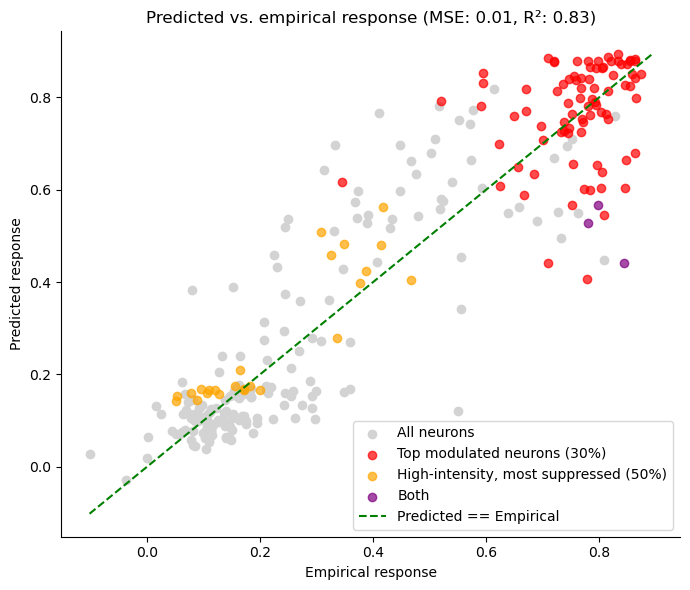

In [ ]:
# PREDICTED VS. MODULATED RESPONSE, INCLUDING HIGH INTENSITY, SUPPRESSED RESPONDERS

# ── Merged plot: top 30% modulated + suppressed high-intensity ─────────────────
modulated_indices = [index for _, index in modulated_10p]
is_modulated = np.isin(range(len(Y_test)), modulated_indices)

# Points can belong to both groups — define three display categories
both        = is_modulated & suppressed_mask
mod_only    = is_modulated & ~suppressed_mask
supp_only   = suppressed_mask & ~is_modulated
neither     = ~is_modulated & ~suppressed_mask

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(Y_test[neither],   Y_pred[neither],   alpha=1, color="lightgray", label="All neurons")
ax.scatter(Y_test[mod_only],  Y_pred[mod_only],  alpha=0.7, color="red",    label="Top modulated neurons (30%)")
ax.scatter(Y_test[supp_only], Y_pred[supp_only], alpha=0.7, color="orange",   label="High-intensity, most suppressed (50%)")
ax.scatter(Y_test[both],      Y_pred[both],      alpha=0.7, color="purple",    label="Both")

min_val = min(Y_test.min(), Y_pred.min())
max_val = max(Y_test.max(), Y_pred.max())
ax.plot([min_val, max_val], [min_val, max_val],
        color="green", linestyle="--", label="Predicted == Empirical")

ax.set_xlabel("Empirical response")
ax.set_ylabel("Predicted response")
ax.set_title(f"Predicted vs. empirical response (MSE: {mse:.2f}, R²: {r2:.2f})")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("scatter_merged.png", dpi=150, bbox_inches="tight")
plt.savefig("scatter_merged.svg", bbox_inches="tight")
plt.show()
plt.close()

In [1315]:
# ── Full dataset subgroup count ────────────────────────────────────────────────
high_intensity_mask_all = X_all[:, 7] > 15
modulation_all = Y_all - X_all0[:, 5]

high_int_indices_all = np.where(high_intensity_mask_all)[0]
high_int_modulation_all = modulation_all[high_int_indices_all]
threshold_all = np.median(high_int_modulation_all)
suppressed_mask_all = np.zeros(len(Y_all), dtype=bool)
suppressed_mask_all[high_int_indices_all[high_int_modulation_all <= threshold_all]] = True

n_total_all         = len(Y_all)
n_high_int_all      = high_intensity_mask_all.sum()
n_suppressed_all    = suppressed_mask_all.sum()

print(f"Total samples (full dataset):     {n_total_all}")
print(f"High intensity (≥15):             {n_high_int_all} ({100*n_high_int_all/n_total_all:.1f}%)")
print(f"Suppressed subgroup (bottom 50%): {n_suppressed_all} ({100*n_suppressed_all/n_total_all:.1f}% of full dataset, {100*n_suppressed_all/n_high_int_all:.1f}% of high intensity)")

Total samples (full dataset):     994
High intensity (≥15):             192 (19.3%)
Suppressed subgroup (bottom 50%): 96 (9.7% of full dataset, 50.0% of high intensity)


In [1316]:
mse_suppressed = mean_squared_error(Y_test[suppressed_mask], Y_pred[suppressed_mask])
r2_suppressed  = r2_score(Y_test[suppressed_mask], Y_pred[suppressed_mask])

print(f"Suppressed subgroup — MSE: {mse_suppressed:.2f}, R²: {r2_suppressed:.2f}")
print(f"Full test set       — MSE: {mse:.2f}, R²: {r2:.2f}")

Suppressed subgroup — MSE: 0.02, R²: 0.67
Full test set       — MSE: 0.01, R²: 0.83


In [ ]:
# function to generate coordinates for simulation
def generate_grid_coordinates(field_of_view, m):
    # Create a grid of m x m points within the specified field_of_view
    x = np.linspace(0, field_of_view, m)
    y = np.linspace(0, field_of_view, m)
    xv, yv = np.meshgrid(x, y)
    grid_points = np.vstack([xv.ravel(), yv.ravel()]).T  # Shape (m*m, 2)

    # Calculate the center point (electrode_1)
    center_coord = np.array([field_of_view / 2, field_of_view / 2])
    
    return grid_points, center_coord

def generate_elect2(elect_distance, center_coord):
    # Calculate the bottom-left corner point (electrode_2) such that it is `elect_distance` away from the center
    angle = np.arctan2(center_coord[1], center_coord[0])  # Angle to the bottom-left corner
    electrode_2 = center_coord + np.array([
        -elect_distance * np.cos(angle), 
        -elect_distance * np.sin(angle)
    ])
    return electrode_2

In [ ]:
# manually specify a stimulation intensity 
# generate 300 neurons in a 1000um field of view, and predict their response to two electrode stimulation

# calculate electrode distance (fixed) and distance to electrode
def distance(case1, case2):
    dist = math.dist(case1, case2)
    return dist

# calculate angle
def angle(coord_N, coord_A, coord_B):
    # Calculate vectors AN and BN
    vector_AN = np.array(coord_A) - np.array(coord_N)
    vector_BN = np.array(coord_B) - np.array(coord_N)
    
    # Calculate the dot product of AN and BN
    dot_product = np.dot(vector_AN, vector_BN)
    
    # Calculate magnitudes of AN and BN
    magnitude_AN = np.linalg.norm(vector_AN)
    magnitude_BN = np.linalg.norm(vector_BN)
    
    if magnitude_AN == 0 or magnitude_BN == 0:
        return 0
    
    # Calculate the angle in degrees
    cosine_angle = dot_product / (magnitude_AN * magnitude_BN)
    cosine_angle = np.clip(cosine_angle, -1.0, 1.0)
    angle = np.degrees(np.arccos(cosine_angle))
    
    return angle

# transform normalization


In [102]:
from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=2)
gmm.fit(Y_all.reshape(-1, 1))
labels = gmm.predict(Y_all.reshape(-1, 1))

C:\Users\User1\miniconda3\envs\analysis\lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


In [ ]:
# use to check any unexpected behaviour from the simulation, by comparing minimum, maximum and total unique values in a feature
MinMaxFeatures = np.array([
    np.min(X_all, axis=0), # min value
    np.max(X_all, axis = 0), # max value
    [len(np.unique(X_all[:,i])) for i in range(X_all.shape[1])]]).T # total number of values in range

In [ ]:
print(MinMaxFeatures)

[[4.05546791e+00 4.94496940e+02 9.70000000e+02]
 [2.82229330e+01 7.29636579e+02 9.70000000e+02]
 [6.51676327e-01 1.79987172e+02 9.70000000e+02]
 [7.96360160e-03 1.79196742e+02 9.70000000e+02]
 [2.62975865e-03 1.68491425e+02 9.70000000e+02]
 [2.84737541e-02 7.14722376e-01 9.94000000e+02]
 [3.74485176e+02 7.60889378e+02 5.00000000e+00]
 [1.20000000e+01 1.80000000e+01 3.00000000e+00]
 [1.20000000e+01 1.80000000e+01 4.00000000e+00]
 [7.15692085e-01 1.20406910e+02 9.93000000e+02]
 [4.74658935e+01 4.88460927e+02 9.70000000e+02]
 [1.87329384e+02 4.97866292e+02 9.70000000e+02]
 [4.49819729e+04 4.88099874e+05 9.70000000e+02]
 [2.15836249e+00 2.51054501e+00 5.00000000e+00]
 [1.21030773e-05 1.28178340e-04 9.94000000e+02]
 [3.99082098e-04 4.73459854e-01 9.94000000e+02]
 [2.88000000e+02 6.48000000e+02 5.00000000e+00]]


In [ ]:
def calculate_electric_field_norm_2d(distA, distB, coords, I1, I2, sigma):
    """
    Calculate the norm of the electric field at a point (x, y) due to two point electrodes in 2D.
    
    Parameters:
    distA : float - Distance from observation point to electrode 1
    distB : float - Distance from observation point to electrode 2
    coords : array-like - [x, y, x1, y1, x2, y2]
               - (x, y): Observation point coordinates
               - (x1, y1): Coordinates of the first electrode
               - (x2, y2): Coordinates of the second electrode
    I1 : float - Current of the first electrode (A)
    I2 : float - Current of the second electrode (A)
    sigma : float - Conductivity of the medium (S/m)
    
    Returns:
    float - The norm of the total electric field (V/m)
    """
    
    # Convert current from μA to A
    I1 = I1 / 1e6  # Convert from μA to A
    I2 = I2 / 1e6  # Convert from μA to A
    
    # Convert distances from µm to m
    x, y, x1, y1, x2, y2 = [coord / 1e6 for coord in coords]
    distA = distA / 1e6
    distB = distB / 1e6
    
    # Define the constant term (1 / (2 * pi * sigma))
    k = 1 / (2 * np.pi * sigma)
    
    # Calculate the components of the electric field due to electrode 1
    E1_x = k * I1 * (x - x1) / distA**2
    E1_y = k * I1 * (y - y1) / distA**2

    # Calculate the components of the electric field due to electrode 2
    E2_x = k * I2 * (x - x2) / distB**2
    E2_y = k * I2 * (y - y2) / distB**2

    # Total electric field components
    E_total_x = E1_x + E2_x
    E_total_y = E1_y + E2_y

    # Calculate the norm of the total electric field
    E_norm = np.sqrt(E_total_x**2 + E_total_y**2)

    return E_norm

In [ ]:
## VISUAL CORTEX SIMULATION

field_of_view = 500  # size of field of view in um
m = 20  # how many neurons per row, total is mxm
n_neurons = m * m
elect_distances = [500] #400, 450, 500, 550, 600
stim_intensities = [12] #12, 13, 15, 18

# Generate grid coordinates and electrode 1 position
grid_points, electrode_1 = generate_grid_coordinates(field_of_view, m)

# Load the pre-trained MinMaxScaler and MLPRegressor model
loaded_scaler = joblib.load("C:/Users/User1/Documents/Victor/minmax_scaler.pkl")
# regr = joblib.load("C:/Users/User1/Documents/Victor/regr_model.pkl")  # Adjust path as needed

# Initialize summary of the predicted responses
summary_matrix = np.zeros((len(elect_distances), len(stim_intensities), n_neurons))

# Iterate over each combination of stim_intensity_1, stim_intensity_2, and elect_distance
for i, elect_distance in enumerate(elect_distances):
    electrode_2 = generate_elect2(elect_distance, electrode_1)
    
    for j, stim_1 in enumerate(stim_intensities):
        for k, stim_2 in enumerate(stim_intensities):
            # Create the X_matrix for current parameter set
            X_matrix = np.zeros((n_neurons, 17))
            
            for n in range(n_neurons):
                distA = distance(grid_points[n, :], electrode_1)
                distB = distance(grid_points[n, :], electrode_2)
                E_norm = calculate_electric_field_norm_2d(
                    distA, distB, 
                    [grid_points[n, 0], grid_points[n, 1], electrode_1[0], electrode_1[1], electrode_2[0], electrode_2[1]], 
                    I1=stim_1, I2=stim_2, sigma=0.23)
                
                X_matrix[n, 0] = distA
                X_matrix[n, 1] = distB
                X_matrix[n, 2] = angle(grid_points[n, :], electrode_1, electrode_2)
                X_matrix[n, 3] = angle(electrode_1, electrode_2, grid_points[n, :])
                X_matrix[n, 4] = angle(electrode_2, grid_points[n, :], electrode_1)
                X_matrix[n, 5] = random.uniform(MinMaxFeatures[5, 0], MinMaxFeatures[5, 1])  # prestimulation range
                X_matrix[n, 6] = elect_distance
                X_matrix[n, 7] = stim_1
                X_matrix[n, 8] = stim_2
                X_matrix[n, 9] = E_norm*100  # electric field

            # Normalize the feature matrix
                sim_mmscaled[n,:] = loaded_scaler.transform(X_matrix[n,0:10].reshape(-1, 1))
            
                X_matrix[n, 10] = np.sqrt(distA*distB) #geometric mean
                X_matrix[n, 11] = (distA+distB)/2 #mean distance
                X_matrix[n, 12] = (distA+distB/2)**2 #square of mean distance
                X_matrix[n, 13] = np.log10(stim_1*stim_2) #log of stimulation intensity
                X_matrix[n, 14] = ((stim_1+stim_2)/2)/(distA+distB)**2
                X_matrix[n, 15] = stim_1**2+stim_2**2
                X_matrix[n, 16] = distA*distB*np.cos(angle(grid_points[n, :], electrode_1, electrode_2))

            sim_mmscaled = np.hstack((sim_mmscaled, X_matrix[:,10:]))
            # Predict the response using the MLPRegressor model
            Y_vector = regr.predict(sim_mmscaled)

            # Store in the summary matrix
            summary_matrix[i, j, :] = Y_vector

# Visualization of an example grid color-coded by response intensity
example_index = 0  # Choose an index for elect_distance and stim_intensity combination to visualize
example_response = summary_matrix[example_index, example_index, :].reshape((m, m))
example_response_inv = example_response # (inv_boxcox(example_response, 1))


plt.figure(figsize=(10, 8))
plt.imshow(example_response_inv, cmap='viridis', extent=[0, field_of_view, 0, field_of_view])
plt.colorbar(label='Predicted Response Intensity')
plt.title('Example Response Grid (Color-coded)')
plt.xlabel('X Coordinate (um)')
plt.ylabel('Y Coordinate (um)')
plt.scatter([electrode_1[0], electrode_2[0]], [electrode_1[1], electrode_2[1]], color='red', marker='o', s=100, label='Electrodes')
plt.text(electrode_1[0], electrode_1[1], 'E1', color='white', ha='center', va='center', fontsize=10, fontweight='bold')
plt.text(electrode_2[0], electrode_2[1], 'E2', color='white', ha='center', va='center', fontsize=10, fontweight='bold')
plt.legend(loc='upper right')

plt.show()

In [120]:
MinMaxFeatures2 = np.array([
    np.min(X_matrix, axis=0), # min value
    np.max(X_matrix, axis = 0), # max value
    [len(np.unique(X_matrix[:,i])) for i in range(X_matrix.shape[1])]]).T # total number of values in range

for i in range(MinMaxFeatures2.shape[0]):
    print(MinMaxFeatures[i,0], " -- ", MinMaxFeatures2[i,0])
    print(MinMaxFeatures[i,1], " -- ", MinMaxFeatures2[i,1])
    print(MinMaxFeatures[i,2], " -- ", MinMaxFeatures2[i,2])

4.055467913817092  --  18.60807318911964
494.49693963562606  --  353.5533905932738
970.0  --  103.0
28.222933033262045  --  146.44660940672625
729.6365787897425  --  853.5533905932739
970.0  --  210.0
0.6516763274813305  --  0.0
179.9871722813598  --  180.0
970.0  --  196.0
0.007963601597882987  --  0.0
179.19674179425647  --  180.0
970.0  --  181.0
0.002629758654803515  --  0.0
168.49142461209647  --  35.264389682754654
970.0  --  194.0
0.02847375412079559  --  0.029180335045133704
0.7147223760575554  --  0.7137851392195615
994.0  --  400.0
374.48517563449695  --  500.0
760.889378005108  --  500.0
5.0  --  1.0
12.0  --  12.0
18.0  --  12.0
3.0  --  1.0
12.0  --  12.0
18.0  --  12.0
4.0  --  1.0
0.7156920849119085  --  0.2153270368038591
120.40690953863746  --  46.22553222219853
993.0  --  208.0
47.46589345312092  --  549.342056733905
488.4609266056393  --  549.342056733905
970.0  --  1.0
187.3293839098616  --  603.5533905932739
497.8662917244648  --  603.5533905932739
970.0  --  1.0
4

In [111]:
np.hstack((grid_points[n, :], electrode_1, electrode_2))

array([  0.        ,   0.        , 250.        , 250.        ,
         2.51262658,   2.51262658])